# Гетероядерные спектры NMRexp: 19F, 31P, 11B, 29Si

1. Сколько спектров каждого ядра (таблица 1).
2. Какая доля train / val / test их имеет (таблица 2).
3. Растворители, мультиплетности и константы J (рис. 1, 2).
4. Число сигналов, сдвиги и согласованность спектров со структурой (рис. 3, таблица 3).

Ядра: `19F` = `19F NMR`; `31P` = `31P NMR` + `P NMR` + `{1H}31P NMR`; `11B` = `11B NMR` + `B NMR`; `29Si` = `29Si NMR` + `Si NMR`.

Молекулы сопоставляются с нашими выборками по каноническому SMILES без стереохимии — тому же ключу, по которому `prepare_nmrexp.py` делит данные.

In [1]:
RAW_PATH = "data/nmrexp/raw/NMRexp_10to24_1_1004.parquet"
DATA_DIR = "data/nmrexp/processed"
SOLVENT = "CDCl3"  # растворитель, на котором обучена модель
CACHE_PATH = "data/nmrexp/processed/other_nuclei_cache.pkl"

In [2]:
import os, sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "analysis").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "analysis"))
import other_nuclei_lib as O

pd.set_option("display.width", 200, "display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "legend.fontsize": 8, "axes.titlesize": 10, "axes.labelsize": 9})
NUCLEI = ["19F", "31P", "11B", "29Si"]
COLORS = {"19F": "#2ca02c", "31P": "#ff7f0e", "11B": "#9467bd", "29Si": "#8c564b"}

# Первый запуск ~5 минут (канонизация SMILES), дальше читается из кэша за секунды.
# Удалите CACHE_PATH, если пересобрали выборки или поменяли other_nuclei_lib.py.
spec, splits = O.load_tables(RAW_PATH, DATA_DIR, CACHE_PATH)
spec["split"] = spec["key"].map(dict(zip(splits["key"], splits["split"]))).fillna("нет в выборках")
cd = spec[(spec.NMR_solvent == SOLVENT) & spec.parsed & spec.in_range]

## Таблица 1. Сколько спектров каждого ядра

| столбец | что значит |
|---|---|
| `spectra` | всего спектров ядра в NMRexp (все растворители) |
| `molecules` | уникальных молекул с таким спектром |
| `spectra_CDCl3` | спектров в CDCl3, у которых удалось разобрать пики |
| `molecules_CDCl3` | молекул с таким спектром в CDCl3 |
| `in_our_splits` | доля молекул из `molecules_CDCl3`, которые уже есть в наших train/val/test |
| `new_molecules` | молекулы со спектром в CDCl3, которых нет в наших выборках (нет подходящего 1H/13C) |

In [3]:
t1 = pd.DataFrame({
    "spectra": spec.groupby("nucleus").size(),
    "molecules": spec.groupby("nucleus")["key"].nunique(),
    "spectra_CDCl3": cd.groupby("nucleus").size(),
    "molecules_CDCl3": cd.groupby("nucleus")["key"].nunique(),
    "in_our_splits": cd[cd.split != "нет в выборках"].groupby("nucleus")["key"].nunique() / cd.groupby("nucleus")["key"].nunique(),
    "new_molecules": cd[cd.split == "нет в выборках"].groupby("nucleus")["key"].nunique(),
}).reindex(NUCLEI)
display(t1)

,spectra,molecules,spectra_CDCl3,molecules_CDCl3,in_our_splits,new_molecules
nucleus,,,,,,
19F,197186,176969,177481,159233,0.9690,4935
31P,33456,29758,29941,26559,0.9565,1156
11B,17142,14988,14041,12152,0.9567,526
29Si,2397,2294,2095,2010,0.9771,46


## Таблица 2. Какая доля train / val / test имеет такие спектры (CDCl3)

Строки — выборка, столбцы — ядро. Три блока:
- **molecules** — сколько молекул выборки имеют спектр этого ядра;
- **share_molecules** — какая это доля всех молекул выборки;
- **share_cases** — доля примеров: пар спектров 1H/13C, как в `evaluate.py`; у молекулы с несколькими спектрами примеров несколько.

`any` — есть хотя бы один гетероядерный спектр. Строка `total` в первой колонке — размер выборки.

In [4]:
has = {n: set(cd[cd.nucleus == n]["key"]) for n in NUCLEI}
for n in NUCLEI:
    splits[n] = splits["key"].isin(has[n])
splits["any"] = splits[NUCLEI].any(axis=1)
splits["cases"] = splits[["n_13C", "n_1H"]].max(axis=1)
cols = NUCLEI + ["any"]
g = splits.groupby("split")
t2 = pd.concat({
    "molecules": g[cols].sum().astype(int),
    "share_molecules": g[cols].mean(),
    "share_cases": g.apply(lambda d: (d[cols].mul(d["cases"], axis=0)).sum() / d["cases"].sum()),
}, axis=1).reindex(["train", "val", "test"])
t2.insert(0, ("total", "molecules"), g.size())
display(t2)

total molecules                            share_molecules                             share_cases                            
      molecules       19F    31P   11B  29Si     any             19F    31P    11B   29Si    any         19F    31P    11B   29Si    any
split                                                                                                                                   
train    932272    110182  18047  8607  1456  135124          0.1182 0.0194 0.0092 0.0016 0.1449      0.1185 0.0190 0.0111 0.0016 0.1468
val      265504     31397   5090  2361   395   38345          0.1183 0.0192 0.0089 0.0015 0.1444      0.1181 0.0187 0.0099 0.0016 0.1447
test     133558     15872   2734  1174   163   19455          0.1188 0.0205 0.0088 0.0012 0.1457      0.1174 0.0203 0.0107 0.0013 0.1462

## Рис. 1. Растворители (все спектры)

- **Ось X** — растворитель: 8 самых частых, остальные в «прочие».
- **Ось Y** — доля спектров ядра в этом растворителе.

Цвет — ядро.

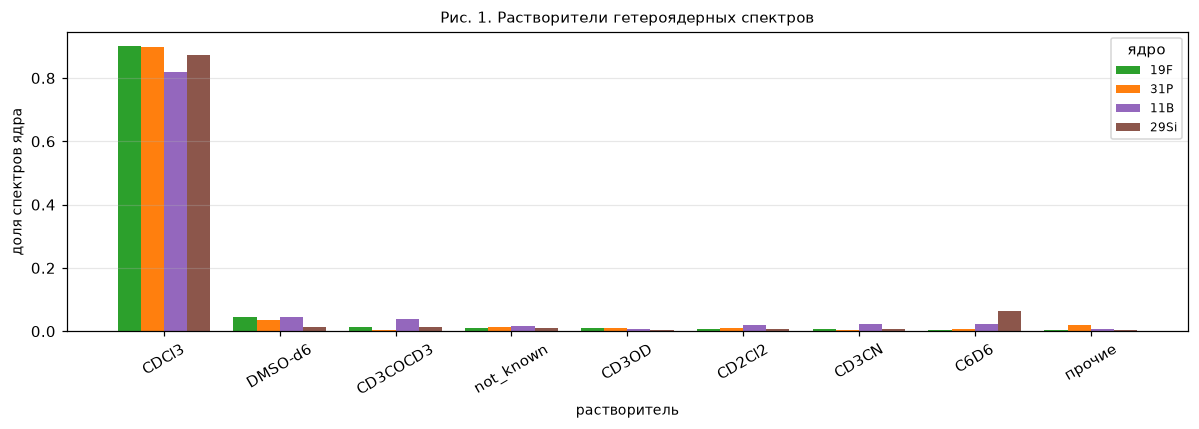

In [5]:
top = spec["NMR_solvent"].value_counts().index[:8]
labels = list(top) + ["прочие"]
fig, ax = plt.subplots(figsize=(11, 4))
for i, n in enumerate(NUCLEI):
    v = spec[spec.nucleus == n]["NMR_solvent"].where(lambda s: s.isin(top), "прочие").value_counts(normalize=True)
    ax.bar(np.arange(len(labels)) + (i - 1.5) * 0.2, v.reindex(labels).fillna(0).values, width=0.2, color=COLORS[n], label=n)
ax.set_xticks(np.arange(len(labels)), labels, rotation=30)
ax.set_xlabel("растворитель"); ax.set_ylabel("доля спектров ядра")
ax.set_title("Рис. 1. Растворители гетероядерных спектров"); ax.legend(title="ядро"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## Рис. 2. Мультиплетности и константы J (CDCl3)

- **Мультиплетности:** доля сигналов ядра с каждой меткой (10 самых частых по всем ядрам, остальные в «прочие»). Сигнал без метки и без J записан как `s`; в таких спектрах метка часто просто не указана, например при развязке от протонов.
- **Число констант J:**
  - ось X — сколько констант указано у сигнала;
  - ось Y — доля сигналов, логарифмическая шкала.
- **Значения J:**
  - ось X — J в Гц (до 300);
  - ось Y — число констант, логарифмическая шкала.
  - Большие J — прямые взаимодействия: ¹J(P,H), ¹J(P,F), ²J(F,F) в CF₂.

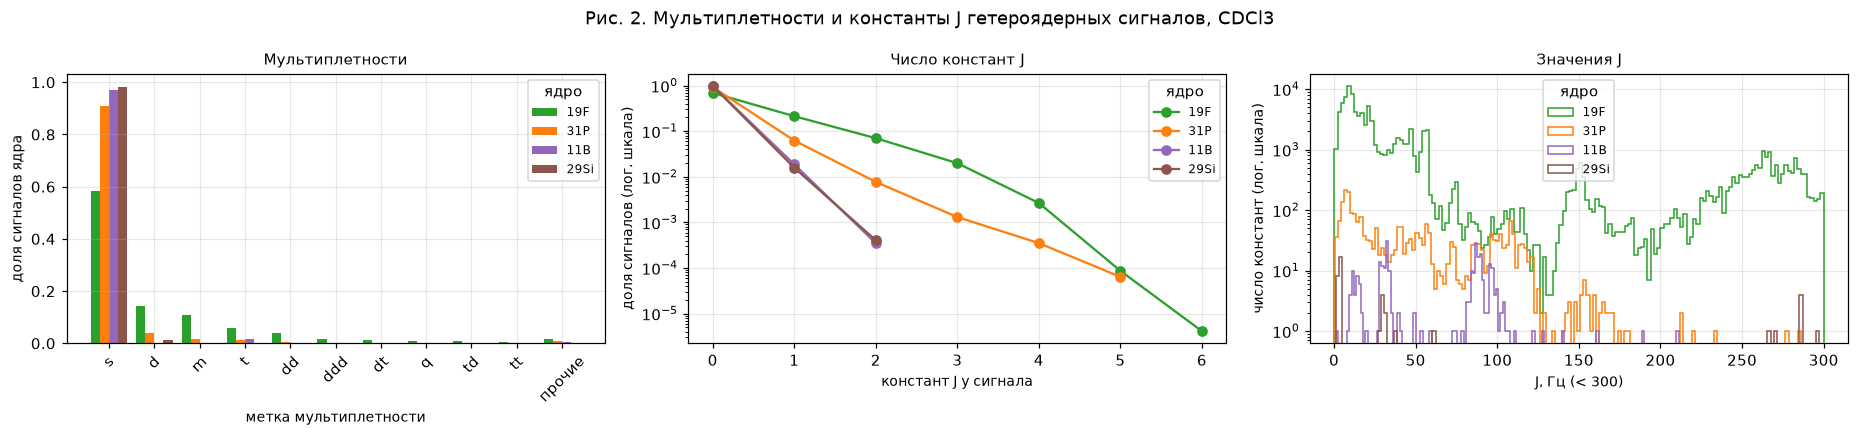

In [6]:
top_m = [m for m, _ in Counter(m for ms in cd["multiplicities"] for m in ms).most_common(10)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for i, n in enumerate(NUCLEI):
    sub = cd[cd.nucleus == n]
    mc = pd.Series(Counter(m for ms in sub["multiplicities"] for m in ms))
    v = pd.concat([mc.reindex(top_m).fillna(0), pd.Series({"прочие": mc.drop(top_m, errors="ignore").sum()})]) / mc.sum()
    axes[0].bar(np.arange(len(v)) + (i - 1.5) * 0.2, v.values, width=0.2, color=COLORS[n], label=n)
    nj = pd.Series(Counter(len(c) for cs in sub["couplings"] for c in cs)).sort_index()
    axes[1].plot(nj.index, nj.values / nj.sum(), marker="o", color=COLORS[n], label=n)
    js = np.array([j for cs in sub["couplings"] for c in cs for j in c])
    if len(js):
        axes[2].hist(js[js < 300], bins=150, histtype="step", color=COLORS[n], label=n)
axes[0].set_xticks(np.arange(len(top_m) + 1), top_m + ["прочие"], rotation=45)
axes[0].set_xlabel("метка мультиплетности"); axes[0].set_ylabel("доля сигналов ядра"); axes[0].set_title("Мультиплетности")
axes[1].set_xlabel("констант J у сигнала"); axes[1].set_ylabel("доля сигналов (лог. шкала)"); axes[1].set_yscale("log"); axes[1].set_title("Число констант J")
axes[2].set_xlabel("J, Гц (< 300)"); axes[2].set_ylabel("число констант (лог. шкала)"); axes[2].set_yscale("log"); axes[2].set_title("Значения J")
for ax in axes: ax.legend(title="ядро"); ax.grid(alpha=0.3)
fig.suptitle("Рис. 2. Мультиплетности и константы J гетероядерных сигналов, CDCl3")
plt.tight_layout(); plt.show()

## Рис. 3. Число сигналов в спектре и химические сдвиги (CDCl3)

- **Слева — число сигналов:**
  - ось X — сколько сигналов в спектре (≥ 10 собрано в 10);
  - ось Y — доля спектров ядра.
  - В легенде медиана.
- **Справа — химические сдвиги**, по панели на ядро:
  - ось X — сдвиг в м.д., обрезано до показанного окна;
  - ось Y — число сигналов.
  - Нужно, чтобы выбрать масштаб Фурье-признаков сдвига для новой модальности.

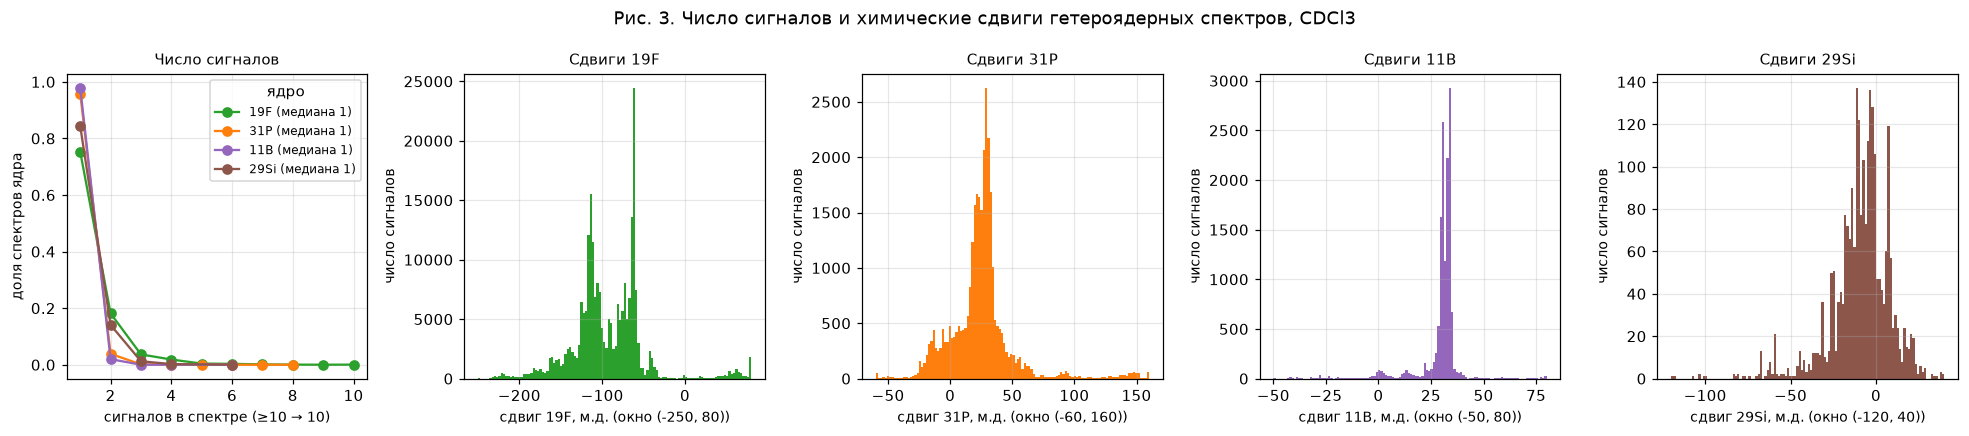

In [7]:
fig = plt.figure(figsize=(18, 4))
ax = fig.add_subplot(1, 5, 1)
for n in NUCLEI:
    sub = cd[cd.nucleus == n]["n_signals"]
    v = sub.clip(upper=10).value_counts(normalize=True).sort_index()
    ax.plot(v.index, v.values, marker="o", color=COLORS[n], label=f"{n} (медиана {sub.median():.0f})")
ax.set_xlabel("сигналов в спектре (≥10 → 10)"); ax.set_ylabel("доля спектров ядра")
ax.set_title("Число сигналов"); ax.legend(title="ядро"); ax.grid(alpha=0.3)
windows = {"19F": (-250, 80), "31P": (-60, 160), "11B": (-50, 80), "29Si": (-120, 40)}
for i, n in enumerate(NUCLEI):
    ax = fig.add_subplot(1, 5, i + 2)
    s = np.concatenate([np.array(x) for x in cd[cd.nucleus == n]["shifts"]])
    ax.hist(np.clip(s, *windows[n]), bins=120, color=COLORS[n])
    ax.set_xlabel(f"сдвиг {n}, м.д. (окно {windows[n]})"); ax.set_ylabel("число сигналов"); ax.set_title(f"Сдвиги {n}"); ax.grid(alpha=0.3)
fig.suptitle("Рис. 3. Число сигналов и химические сдвиги гетероядерных спектров, CDCl3")
plt.tight_layout(); plt.show()

## Таблица 3. Главные свойства спектров (CDCl3)

| столбец | что значит |
|---|---|
| `signals_median`, `signals_p95`, `signals_max` | медиана, 95-й перцентиль и максимум числа сигналов в спектре |
| `one_signal` | доля спектров ровно с одним сигналом |
| `with_J` | доля сигналов, у которых указана хотя бы одна константа J |
| `shift_p1`, `shift_p99` | 1-й и 99-й перцентили сдвига, м.д.: рабочий диапазон для признаков |
| `spectra_per_molecule` | в среднем спектров на молекулу |
| `atoms_median` | медиана числа атомов элемента в молекуле (F для 19F и т. д.) |
| `consistent` | доля спектров, где сигналов ровно столько, сколько топологически неэквивалентных атомов элемента; при < 1 сигналы слились, не указаны или лишние |
| `fewer`, `more` | доли спектров, где сигналов меньше или больше, чем неэквивалентных атомов |
| `duplicates` | доля спектров, полностью повторяющих другой спектр той же молекулы |

In [8]:
by = cd.groupby("nucleus")
dev = cd["n_signals"] - cd["n_element_distinct"]
shifts = by["shifts"].apply(lambda s: np.concatenate([np.array(x) for x in s]))
t3 = pd.DataFrame({
    "signals_median": by["n_signals"].median(),
    "signals_p95": by["n_signals"].quantile(0.95),
    "signals_max": by["n_signals"].max(),
    "one_signal": (cd["n_signals"] == 1).groupby(cd["nucleus"]).mean(),
    "with_J": by["couplings"].apply(lambda s: np.mean([len(c) > 0 for cs in s for c in cs])),
    "shift_p1": shifts.map(lambda s: np.percentile(s, 1)),
    "shift_p99": shifts.map(lambda s: np.percentile(s, 99)),
    "spectra_per_molecule": by.size() / by["key"].nunique(),
    "atoms_median": by["n_element"].median(),
    "consistent": (dev == 0).groupby(cd["nucleus"]).mean(),
    "fewer": (dev < 0).groupby(cd["nucleus"]).mean(),
    "more": (dev > 0).groupby(cd["nucleus"]).mean(),
    "duplicates": by.apply(lambda g: 1 - g.groupby("key")["fingerprint"].nunique().sum() / len(g)),
}).reindex(NUCLEI)
display(t3)

,signals_median,signals_p95,signals_max,one_signal,with_J,shift_p1,shift_p99,spectra_per_molecule,atoms_median,consistent,fewer,more,duplicates
nucleus,,,,,,,,,,,,,
19F,1.0000,3.0000,67,0.7534,0.3066,-203.1000,68.0944,1.1146,3.0000,0.8688,0.0124,0.1188,0.0189
31P,1.0000,1.0000,8,0.9588,0.0719,-25.0000,144.3000,1.1273,1.0000,0.9772,0.0038,0.0190,0.0196
11B,1.0000,1.0000,6,0.9799,0.0191,-24.2560,49.4700,1.1554,1.0000,0.9618,0.0339,0.0043,0.0256
29Si,1.0000,2.0000,6,0.8439,0.0162,-67.6390,24.0070,1.0423,1.0000,0.9814,0.0043,0.0143,0.0076
